# RQAOA на CPU

**Версия 0.1.0a3.** Этот ноутбук проходит полный сценарий первого RQAOA:
небольшой взвешенный граф → JSON-конфигурация → обучение QAOA и физические
корреляции → выбор пары → точная редукция → точный остаток → восстановление →
проверка энергии → графики → сохранение и повторный анализ.

Используется энергетическая конвенция `E = -C`. RQAOA — эвристика. Точное
решение остатка не доказывает глобальный оптимум исходной задачи. Полный вектор
состояния ограничивает размер графа; эта реализация не масштабируется на 1000
вершин.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from copy import deepcopy
import json
import math

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
import QA_max_cut_lib as qa
from QA_max_cut_lib import GraphFactory, SolverFactory, ExactCPU, WeightedGraph
from QA_max_cut_lib import tools

root = Path.cwd()
if not (root / 'configs').is_dir():
    root = root.parent
assert (root / 'configs').is_dir(), 'Open the notebook from the project or notebooks folder.'
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
output_dir = root / 'notebooks' / '_outputs' / ('rqaoa_' + stamp)
output_dir.mkdir(parents=True, exist_ok=True)
print('QA_max_cut_lib', qa.__version__)
print('Output:', output_dir)


QA_max_cut_lib 0.1.0a4
Output: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\rqaoa_20261102T133403Z_896e40


## 1. Взвешенный граф и точный ориентир

Вершины `10, 20, 30, 40, 50` образуют связную часть; вершина `101` изолирована.
Веса обоих знаков и исходные номера с пропусками проверяют общий контракт задачи.
`ExactCPU` нужен только как независимый ориентир для малого графа.


Nodes: (10, 20, 30, 40, 50, 101)
Edges: ((10, 20, 1.5), (20, 30, -0.5), (10, 30, 2.0), (30, 40, 1.0), (40, 50, 2.5), (10, 50, -1.0))


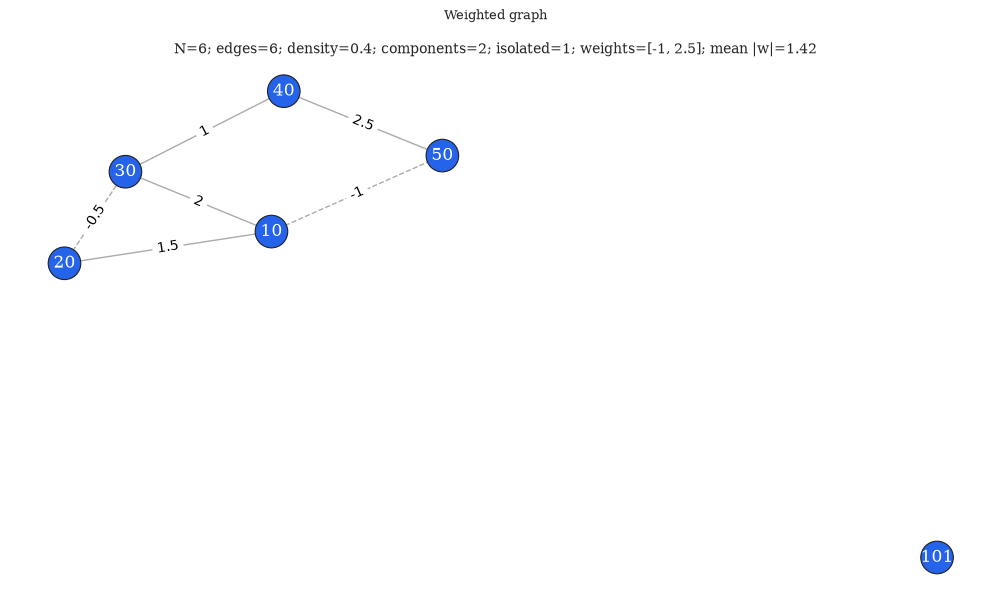

Exact cut: 6.0
Exact energy: -6.0


In [2]:
graph = WeightedGraph(
    edges=[
        (10, 20, 1.5), (20, 30, -0.5), (10, 30, 2.0),
        (30, 40, 1.0), (40, 50, 2.5), (10, 50, -1.0),
    ],
    nodes=[10, 20, 30, 40, 50, 101],
)
print('Nodes:', graph.nodes)
print('Edges:', graph.edges)
figure = tools.plot_graph_info(graph, {'style': {'text_engine': 'mathtext', 'figsize': [10, 6]}})
display(figure)
plt.close(figure)

reference = ExactCPU()
reference.solve(graph, report=0, logs=0)
print('Exact cut:', reference.cut_value)
print('Exact energy:', reference.solution_energy)


## 2. Конфигурация RQAOA

Конфигурация читается из JSON. `finish_at=2` завершает цикл точным решением
остатка из двух вершин. `max_steps=4` уменьшает время учебного запуска;
источник всё равно обучает QAOA и возвращает физические корреляции. Глубина
`p=1`, порядок углов — `gamma_0, beta_0`.


In [3]:
config = tools.load_json(root / 'configs/solvers/rqaoa_cpu.json')
config['output'] = {'report': 0, 'logs': 0, 'color': 'never'}
config['parameters']['finish_at'] = 2
config['parameters']['max_reductions'] = None
config['correlation_source']['optimizer']['parameters']['max_steps'] = 4
algorithm = SolverFactory.from_config(config)
solution = algorithm.solve(graph)
print('Solution:', solution)
print('Cut:', algorithm.cut_value, 'Energy:', algorithm.solution_energy)
print('Reductions:', algorithm.reductions_completed)
print('Source:', algorithm.solution_source)
print('Cut offset:', algorithm.cut_offset)
print('Ising constant:', algorithm.ising_constant)
print('Remaining:', algorithm.remaining_node_order)
print('Resources:', algorithm.resources)


Solution: {10: 1, 40: 1, 101: 1, 30: -1, 20: -1, 50: -1}
Cut: 6.0 Energy: -6.0
Reductions: 3
Source: zero_interaction_residual
Cut offset: 6.0
Ising constant: -6.0
Remaining: [10, 40, 101]
Resources: {'shots_used': 0, 'training_shots': 0, 'correlation_shots': 0, 'readout_shots': 0, 'objective_evaluations': 60, 'optimizer_steps': 12, 'source_attempts': 3, 'source_calls': 3, 'reductions_completed': 3, 'num_stages': 4, 'num_treads': 1}


## 3. Проверка полного решения и энергии

Словарь должен содержать каждую исходную вершину ровно один раз. Значение
разреза пересчитывается прямым суммированием на исходном графе. Инвариант
редукций проверяется отдельно: `C_original = b + C_reduced`.


In [4]:
assert set(solution) == set(graph.nodes)
assert all(type(spin) is int and spin in (-1, 1) for spin in solution.values())
assert math.isclose(algorithm.cut_value, graph.cut_value(solution), abs_tol=1e-12)
assert math.isclose(
    algorithm.cut_value,
    algorithm.cut_offset + algorithm.reduced_cut_value,
    abs_tol=1e-9,
)
assert math.isclose(algorithm.solution_energy, -algorithm.cut_value, abs_tol=1e-12)
assert algorithm.reductions_completed >= 1
print('Full solution and E = -C verified.')


Full solution and E = -C verified.


## 4. `result` и прямые атрибуты

`algorithm.result` — JSON-совместимый снимок последнего запуска. Прямые
результатные атрибуты читают ту же запись: например, `algorithm.cut_value`
совпадает с `result["cut_value"]`.


In [5]:
result = algorithm.result
text = json.dumps(result, ensure_ascii=False, allow_nan=False)
print('JSON characters:', len(text))
print('Result fields:', sorted(result))
assert result['cut_value'] == algorithm.cut_value
assert result['reductions_completed'] == algorithm.reductions_completed
assert result['reduction_history'] == algorithm.reduction_history


JSON characters: 8105
Result fields: ['algorithm_type', 'config', 'correlation_tables', 'correlations', 'cut_offset', 'cut_value', 'data_status', 'expected_cut', 'expected_energy', 'final_reduction_state', 'finished_at', 'graph', 'ising_constant', 'local_optimizer_history', 'node_order', 'num_treads', 'objective_value', 'optimal_angles', 'optimizer_history', 'optimizer_loss', 'package_version', 'parameter_trajectory', 'probabilities', 'reduced_cut_value', 'reduced_solution', 'reduction_history', 'reductions_completed', 'remaining_node_order', 'report', 'resources', 'run_id', 'schema_version', 'seed', 'solution', 'solution_energy', 'solution_source', 'started_at', 'statevector', 'status', 'termination_reason', 'timing', 'worst_cut_value']


## 5. Таблица редукций

Каждая строка относится к слиянию, выполненному **после** получения корреляций.
`selected_weight` — текущий вес пары, `fixed_energy` — вклад после фиксации,
`expected_fixed_energy` — ожидаемый вклад до фиксации. `score` — отдельная
величина выбора, а не корреляция.


In [6]:
rows = []
for event in algorithm.reduction_history:
    rows.append({
        'step': event['step'],
        'removed': event['removed_node'],
        'retained': event['retained_node'],
        'sign': event['sign'],
        'weight': event['selected_weight'],
        'correlation': event['physical_correlation'],
        'score': event['selection_score'],
        'fixed_energy': event['fixed_energy'],
        'expected_fixed_energy': event['expected_fixed_energy'],
        'cut_offset': event['cut_offset'],
        'ising_constant': event['ising_constant'],
        'edges_after': event['edges_after'],
        'mean_abs_weight': event['mean_abs_weight'],
    })
from pandas import DataFrame
display(DataFrame(rows))


,step,removed,retained,sign,weight,correlation,score,fixed_energy,expected_fixed_energy,cut_offset,ising_constant,edges_after,mean_abs_weight
0,1,50,40,-1,2.5,-0.821393,0.821393,-2.5,-2.276741,1.5,-4.00,5,1.2
1,2,20,10,-1,1.5,-0.606064,0.606064,-1.5,-1.204548,2.5,-4.75,3,1.5
2,3,30,10,-1,2.5,-0.689956,0.689956,-2.5,-2.112445,6.0,-6.00,0,NaN


## 6. Веса и энергия редукций

Верхний график показывает вес выбранной пары и средний модуль ненулевого веса.
Нижний — фиксированный и ожидаемый вклады по шагам и накопительно; отдельные
панели показывают `cut_offset` и полную константу Изинга. Их нельзя смешивать
с суммой вкладов выбранных рёбер.


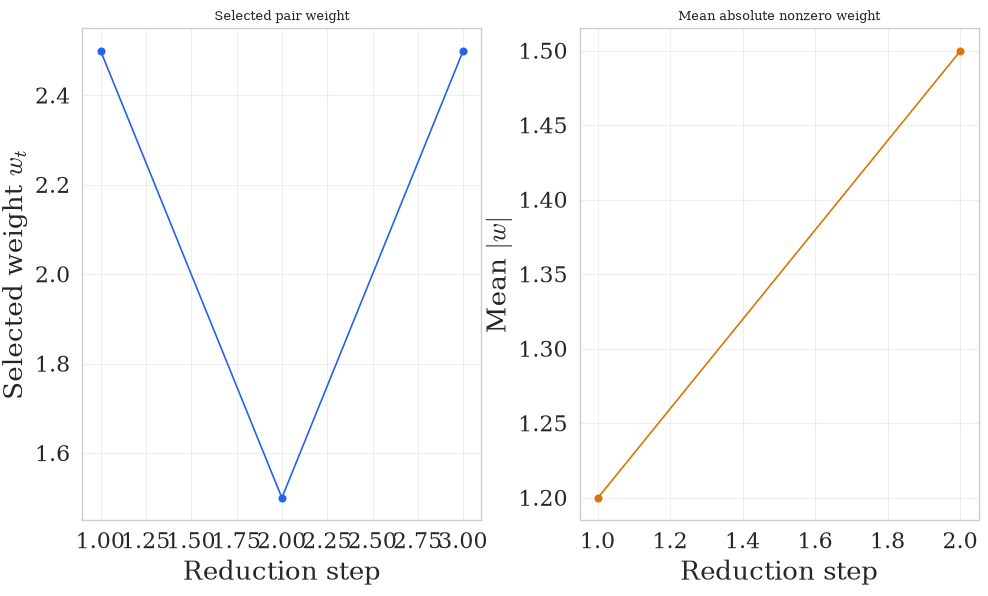

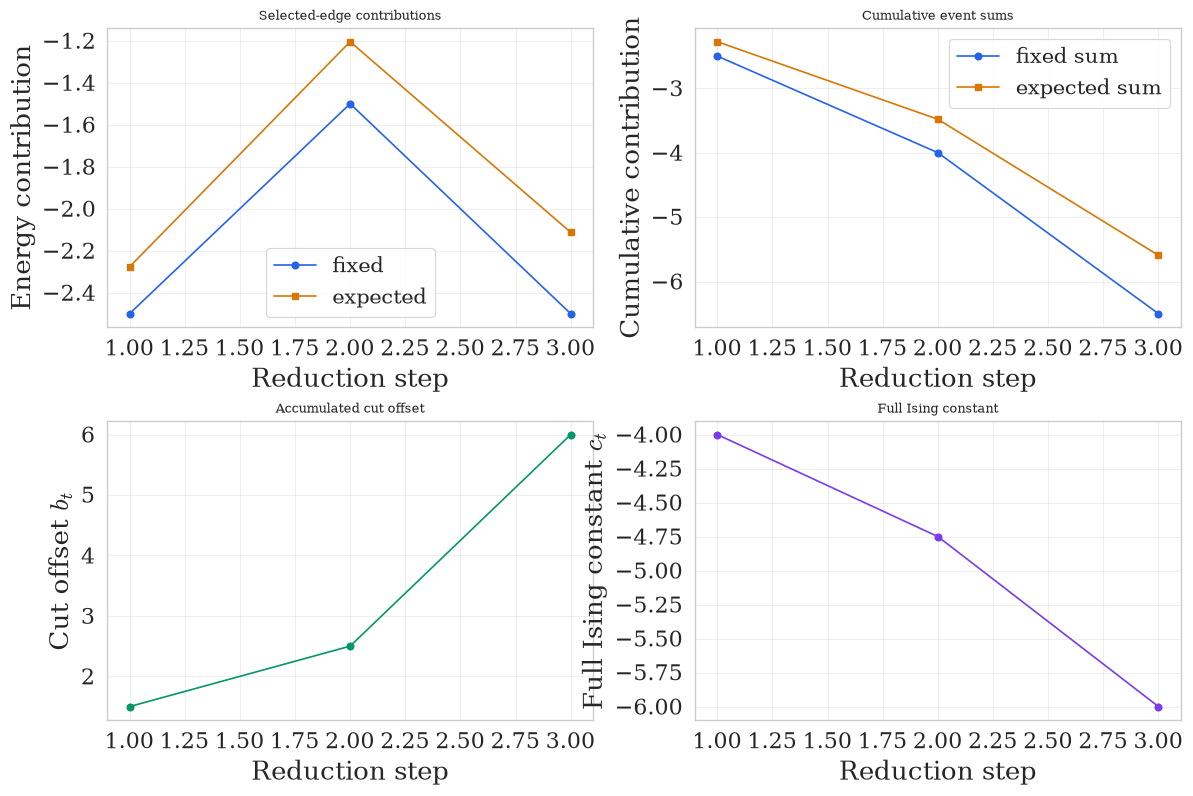

In [7]:
style = {'text_engine': 'mathtext', 'figsize': [10, 6]}
weights_figure = tools.plot_reduction_weights(algorithm, {'style': style})
display(weights_figure)
plt.close(weights_figure)

energy_figure = tools.plot_reduction_energy(algorithm, {'style': {'text_engine': 'mathtext', 'figsize': [12, 8]}})
display(energy_figure)
plt.close(energy_figure)


## 7. Траектории параметров

Для `p=1` обязательна одна пара `(gamma_0, beta_0)`. Для больших `p` число
неупорядоченных пар равно `binomial(2p, 2)`: 6 при `p=2` и 15 при `p=3`.
Плоские панели и 3D-версия используют сохранённые углы без дополнительного
запуска QAOA. В 3D ось Z — номер редукции.


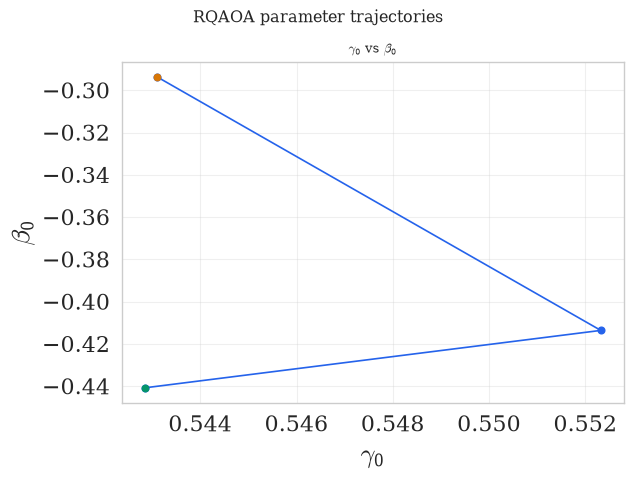

3D traces: 1
3D HTML: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\rqaoa_20261102T133403Z_896e40\reduction_trajectories\reduction_trajectories.html


In [8]:
trajectory_figure = tools.plot_parameter_trajectories(algorithm, {'style': {'text_engine': 'mathtext', 'figsize': [8, 6]}})
display(trajectory_figure)
plt.close(trajectory_figure)

trajectory_3d = tools.plot_parameter_trajectories_3d(algorithm, {
    'save': {
        'path': str(output_dir),
        'filename': 'reduction_trajectories',
        'format': 'html',
        'makedir': True,
        'savedir': True,
        'metadata': True,
    }
})
print('3D traces:', len(trajectory_3d.data))
print('3D HTML:', trajectory_3d.layout.meta['qa_primary'])


## 8. Граф с решением

Вершины двух частей различаются цветом; рёбра разреза выделены. Изолированная
вершина `101` также получает спин.


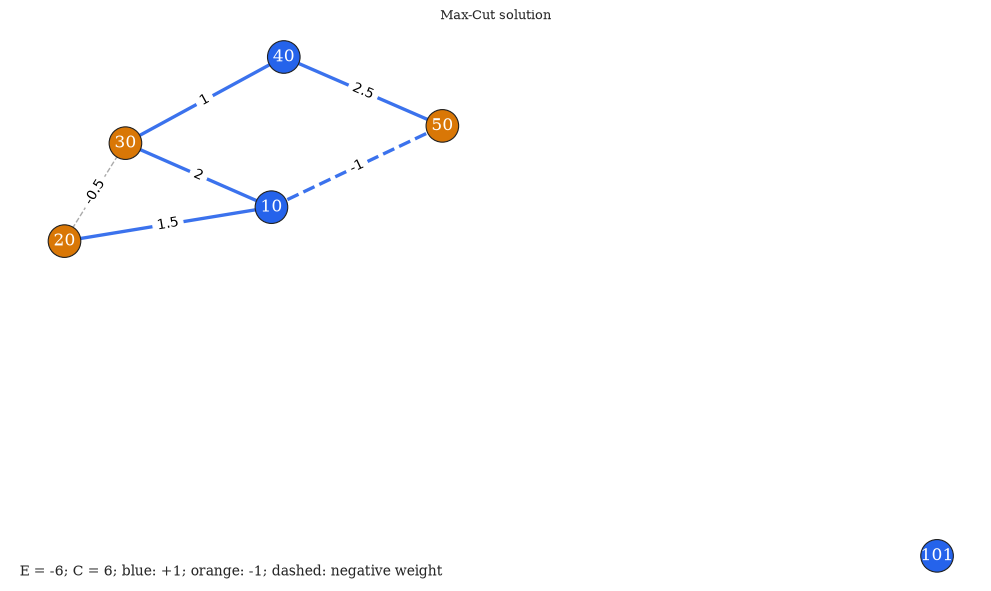

In [9]:
solution_figure = tools.plot_graph_solution(algorithm, config={
    'style': {'text_engine': 'mathtext', 'figsize': [10, 6]},
    'graph': {'weight_labels': True},
})
display(solution_figure)
plt.close(solution_figure)


## 9. Сравнение с перебором

RQAOA не обязан достигать глобального оптимума. Здесь проверяется только
допустимость и качество полученного решения, а не равенство точному максимуму.


In [10]:
print('RQAOA cut:', algorithm.cut_value)
print('Exact cut:', reference.cut_value)
print('Difference:', reference.cut_value - algorithm.cut_value)
assert algorithm.cut_value <= reference.cut_value + 1e-12


RQAOA cut: 6.0
Exact cut: 6.0
Difference: 0.0


## 10. Шотовый режим и строгий бюджет

В шотовом режиме критерий обучения и корреляции оцениваются по выборкам.
Одна корреляционная выборка даёт все пары; счётчики обучения и корреляций
разделены. Остаток после двух редукций решается точно и не расходует шоты.


In [11]:
shots_config = deepcopy(config)
shots_config['parameters'] = {'finish_at': 4, 'max_reductions': 2}
shots_config['correlation_source']['estimation'] = {'mode': 'shots', 'shots_per_evaluation': 64}
shots_config['correlation_source']['correlations'] = {'mode': 'shots', 'shots': 512}
shots_config['correlation_source']['optimizer']['parameters']['max_steps'] = 2
shots_config['limits'] = {'shots_total': 20000}
shots = SolverFactory.from_config(shots_config)
shots_solution = shots.solve(graph)
print('Status:', shots.status, 'Reason:', shots.termination_reason)
print('Source:', shots.solution_source, 'Reductions:', shots.reductions_completed)
print('Shots:', shots.resources['shots_used'])
assert set(shots_solution) == set(graph.nodes)
assert shots.resources['shots_used'] <= 20000
assert shots.resources['readout_shots'] == 0


Status: completed Reason: finish_at
Source: exact_finisher Reductions: 2
Shots: 2304


## 11. Остановка по нулевому бюджету

Лимит меньше обязательной корреляционной выборки не запускает измерение.
Возвращается полное детерминированное решение `all_plus_reduced_fallback`;
статус — `stopped`, причина — `shot_budget`. Это не точное решение большого
остатка и не доказательство оптимальности.


In [12]:
stop_config = deepcopy(shots_config)
stop_config['parameters'] = {'finish_at': 2, 'max_reductions': None}
stop_config['limits'] = {'shots_total': 0}
stopped = SolverFactory.from_config(stop_config)
stopped_solution = stopped.solve(graph)
print('Status:', stopped.status, 'Reason:', stopped.termination_reason)
print('Source:', stopped.solution_source, 'Shots:', stopped.resources['shots_used'])
assert stopped.status == 'stopped'
assert stopped.termination_reason == 'shot_budget'
assert stopped.solution_source == 'all_plus_reduced_fallback'
assert stopped.resources['shots_used'] == 0
assert set(stopped_solution) == set(graph.nodes)


Status: stopped Reason: shot_budget
Source: all_plus_reduced_fallback Shots: 0


## 12. Сохранение и повторный анализ

Основной JSON содержит метаданные и выбранные атрибуты. Повторная запись с тем
же именем не перезаписывает прежний набор. Графики ниже строятся уже из
загруженной записи и не запускают солвер.


Saved JSON: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\rqaoa_20261102T133403Z_896e40\saved\rqaoa_run\rqaoa_run.json


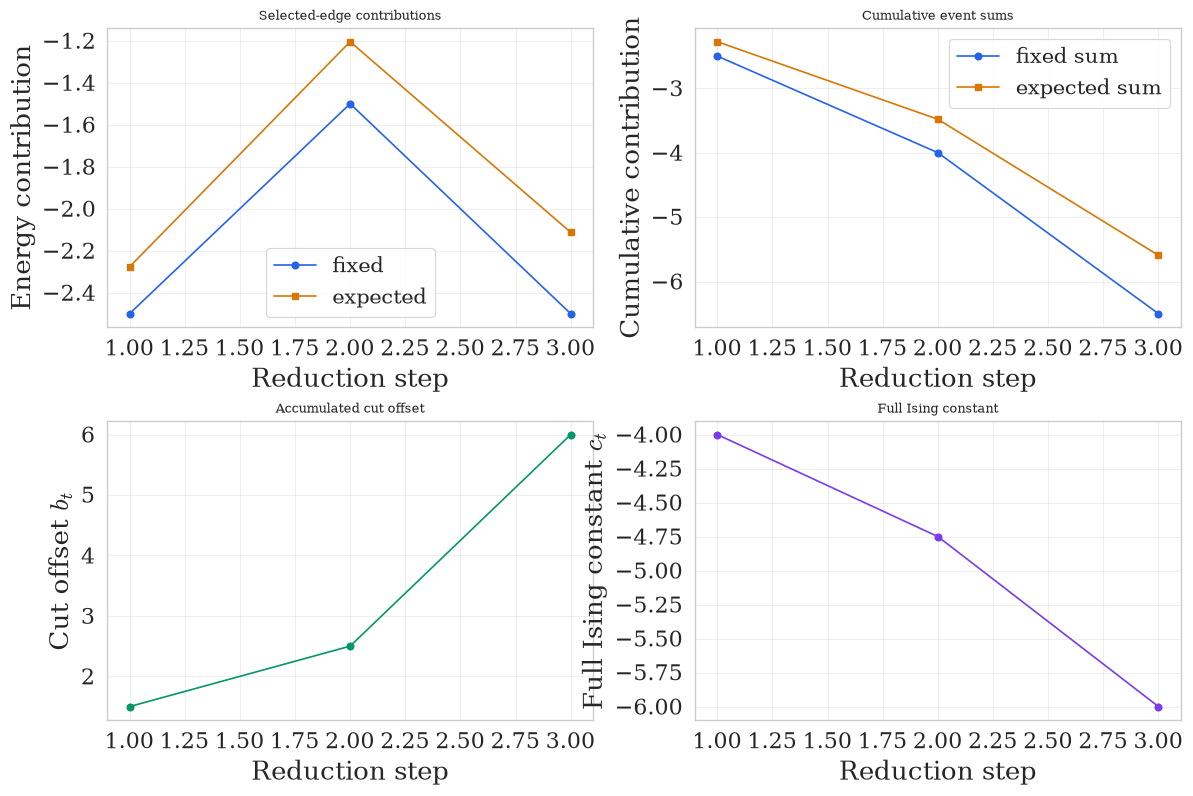

Reloaded 3D HTML: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\notebooks\_outputs\rqaoa_20261102T133403Z_896e40\loaded_trajectories\loaded_trajectories.html


In [13]:
files = tools.save_result(algorithm, {
    'path': str(output_dir / 'saved'),
    'filename': 'rqaoa_run',
    'atts': ['solution', 'cut_value', 'cut_offset', 'ising_constant',
             'reduction_history', 'parameter_trajectory'],
    'savedir': True,
    'makedir': True,
})
print('Saved JSON:', files.primary)
loaded = tools.load_result(files.primary)
assert loaded.solution == algorithm.solution
assert loaded.reduction_history == algorithm.reduction_history
assert loaded.parameter_trajectory == algorithm.parameter_trajectory

loaded_figure = tools.plot_reduction_energy(loaded, {'style': {'text_engine': 'mathtext', 'figsize': [12, 8]}})
display(loaded_figure)
plt.close(loaded_figure)

loaded_3d = tools.plot_parameter_trajectories_3d(loaded, {
    'save': {
        'path': str(output_dir),
        'filename': 'loaded_trajectories',
        'format': 'html',
        'makedir': True,
        'savedir': True,
        'metadata': False,
    }
})
print('Reloaded 3D HTML:', loaded_3d.layout.meta['qa_primary'])


## 13. Итог

Проверены: полный словарь спинов, прямой разрез, инвариант `C_original =
b + C_reduced`, `E = -C`, несколько редукций, точный остаток, шотовый режим,
остановка по строгому бюджету, сохранение и повторное построение графиков.
Аналитический `p=1`, GPU, LS-RQAOA и QAOA-in-QAOA остаются следующими этапами.
